# Méthodes de séparation de sources pour l’analyse de données en astrophysique

Baudouin de Monicault, Ecole Polytechnique et Paul Barbier, Ecole des Ponts

In this problem, we tackle a source separation problem with 3 instances:
- simple linear model.
- complex model.
- real data.
As seen during the lectures, the problem consists in decomposing $X$, the spectral image into $A$ the mixing matrix and $S$ the sources associated to the mixing. 

The simplest model one can come up with is a linear model where $X = AS + N$ where $N$ accounts for noise. and this will be the focus of our first section. In addition to the instances, we know that addivitive Poisson noise is present. Let's see if we can take into account this particularity in the coming sections.

Non-differentiability and unbounded Hessian of the datafidelityterm: inEquation2,thetermL(X|A,S) is not smooth about 0, which rigorously excludes the use of PALM, which requires a smooth data fidelity term.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.palm import PALM
from scripts.gmca import GMCA
from scripts.minvolnmf import minvolNMF, simpleSPA

# Retrieving the data

In [2]:
chandra_pickle = np.load("./data/chandra_data.npy", allow_pickle=True).item()

X_linear_model = chandra_pickle['LinModel']
A_linear_model = chandra_pickle['MixingMatrix']
S_all_models = chandra_pickle['Sources']
X_complex_model = chandra_pickle['ComplexSims']
X_real_data = chandra_pickle['RealData']

print("** shapes **")
print("X_linear_model:", X_linear_model.shape)
print("A_linear_model:", A_linear_model.shape)
print("S_all_models:", S_all_models.shape)
print("X_complex_model:", X_complex_model.shape)
print("X_real_data:", X_real_data.shape)

** shapes **
X_linear_model: (40, 128, 128)
A_linear_model: (40, 3)
S_all_models: (3, 128, 128)
X_complex_model: (40, 230, 230)
X_real_data: (40, 256, 256)


## Linear model

### The sources

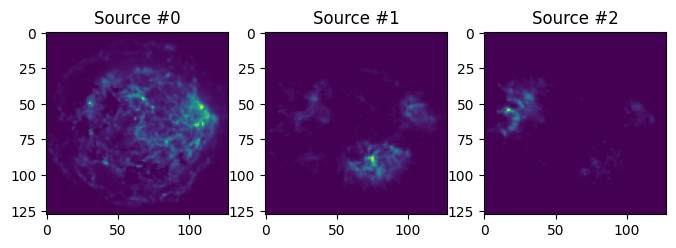

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(8, 24))
for idx, source in enumerate(S_all_models):
    ax[idx].imshow(source)
    ax[idx].set_title(f"Source #{idx}")
plt.show()

### The mixing matrix

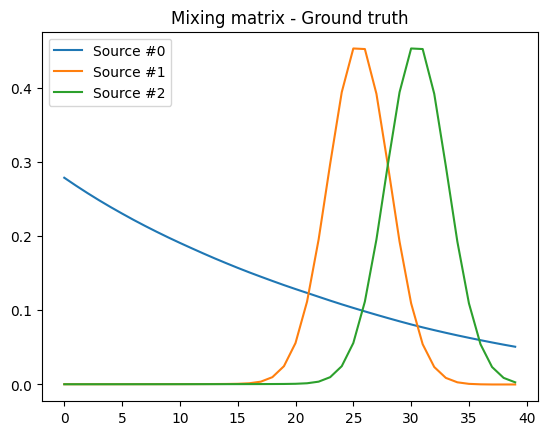

In [25]:
fig, ax = plt.subplots()
for source_idx, source in enumerate(A_linear_model.T):
    ax.plot(source, label=f"Source #{source_idx}")
ax.legend()
ax.set_title("Mixing matrix - Ground truth")
plt.show()

## GMCA

In [26]:
A_est, S_est = GMCA(X_linear_model.reshape(40,-1), n_sources=3, max_iter=100)

### Results

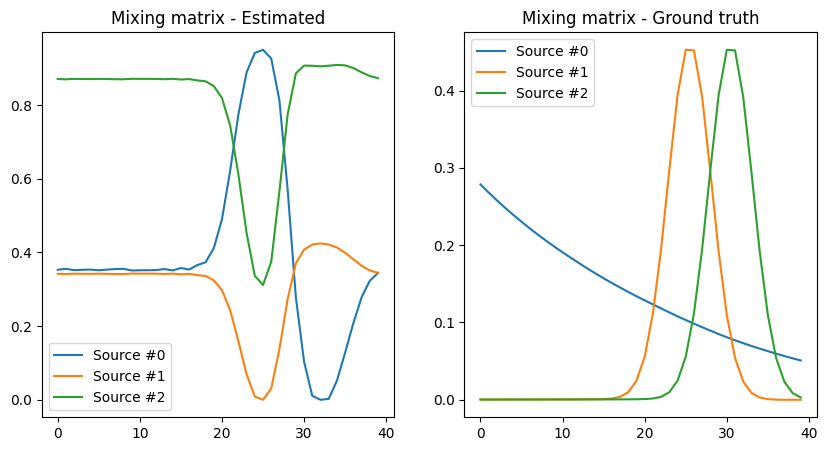

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

GMCA is completely off on this, whatever number of iterations we select and initialisation. Though, it gets some of the resulting mixing so maybe we could leverage it as an initialisation..

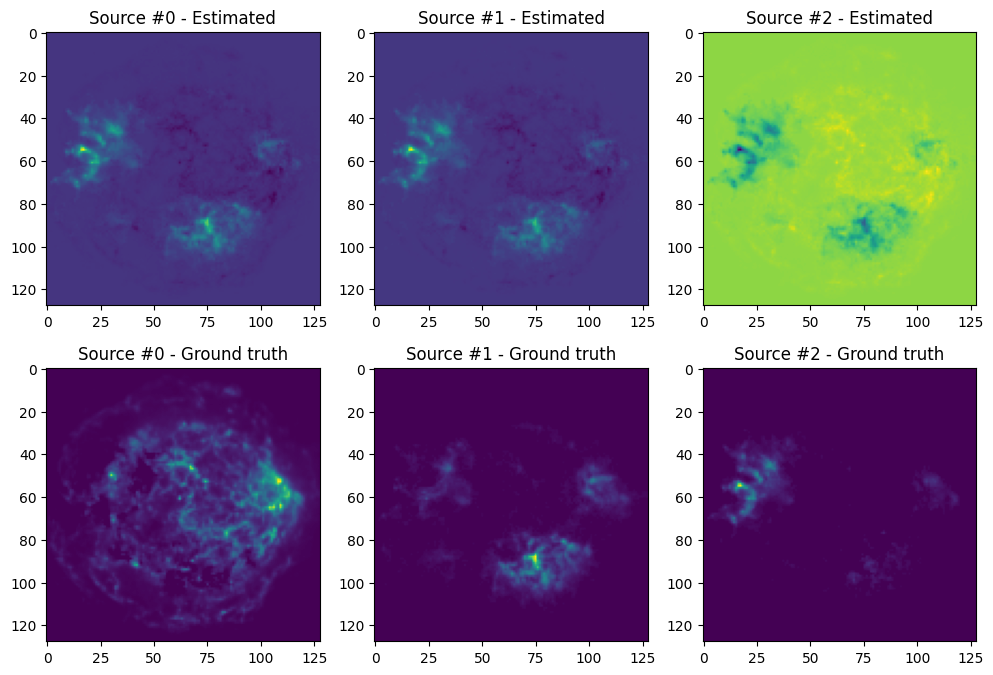

In [28]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(128, 128))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

## PALM method 

In [29]:
A_est, S_est, it = PALM(X_linear_model.reshape(40,-1), A_linear_model, S_all_models.reshape(3,-1), lamb=1e-2, itmax=100)

itmax 100


### Results

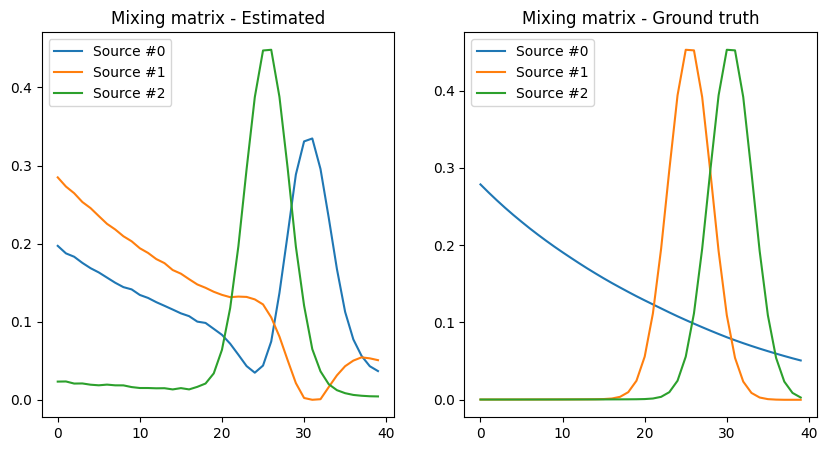

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

We can see in the figure above that the mixing matrix is reconstructed well for most of the spectrum, except for a small range around 30 where sources overlap more significantly. Interestingly, the two rays have different heights in the predicted mixture while they are equal in the ground truth.

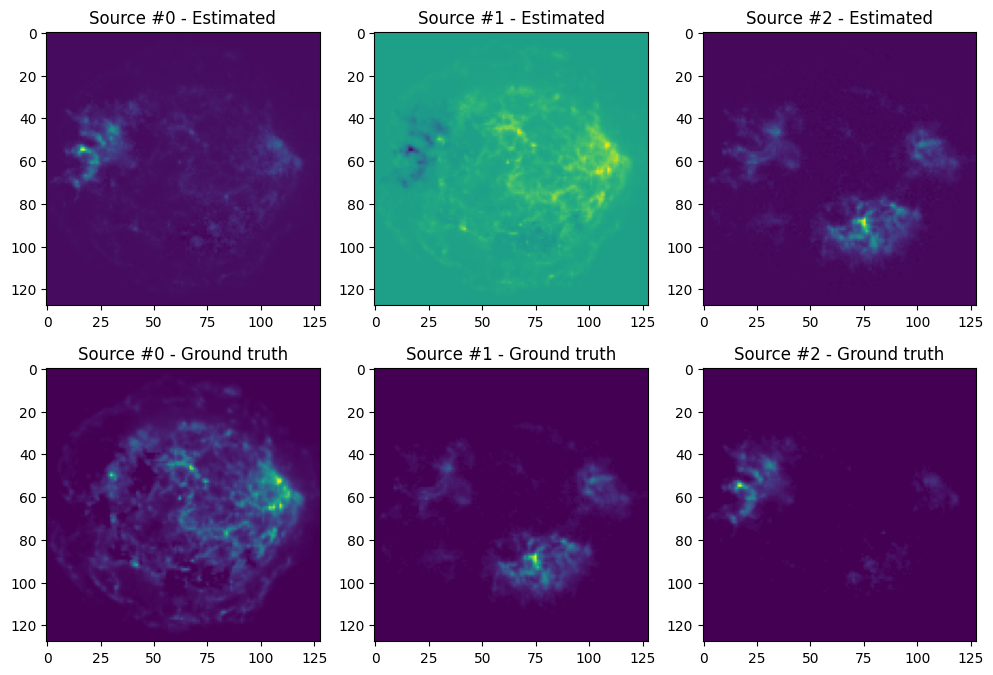

In [31]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(128, 128))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

Even though we miss some details, the source reconstruction quality is visually quite appealing and you can tell which source is which.

## minvolNMF method 

In [32]:
n_sources = 3

X_linear_2d = X_linear_model.reshape(X_linear_model.shape[0], -1)
K_SPA = simpleSPA(X_linear_2d, n_sources)

A_SPA = X_linear_2d[:, K_SPA]
[A_est, S_est, _, _, _] = minvolNMF(X_linear_2d,W=A_SPA,H=0.1 + np.random.rand(A_SPA.shape[1], X_linear_2d.shape[1]),r=n_sources,lamb=1.,maxiter=1000,target=0.05,model=1)

Max residual 280.26786648601205
Max residual 172.81285448171107
Max residual 44.66558415153294
100
200
300
400
500
600
700
800
900


### Results

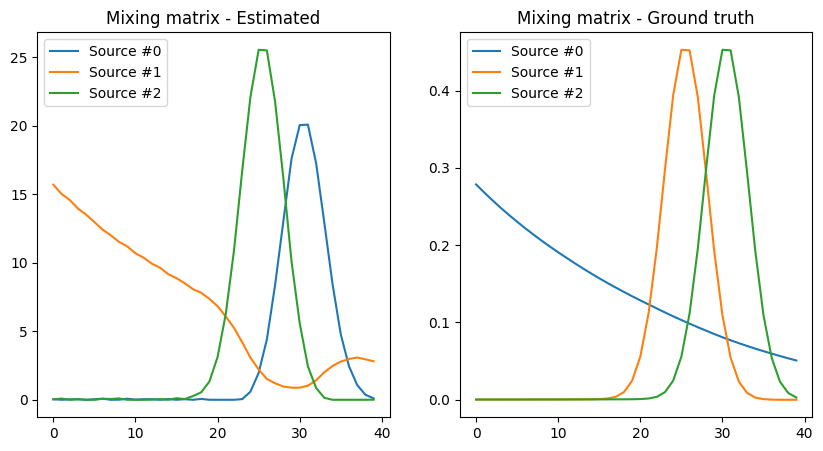

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

minvolNMF leads to better results. There is still a misprediction of the sources around the overlapping area but in the lowest values of $x$, the sources are predicted way better than the previous methods: this methods correctly predicts the mixing for all sources for $x < 20$.

However, the difference in height for the 2 rays is still present and this method doesn't solve this issue.

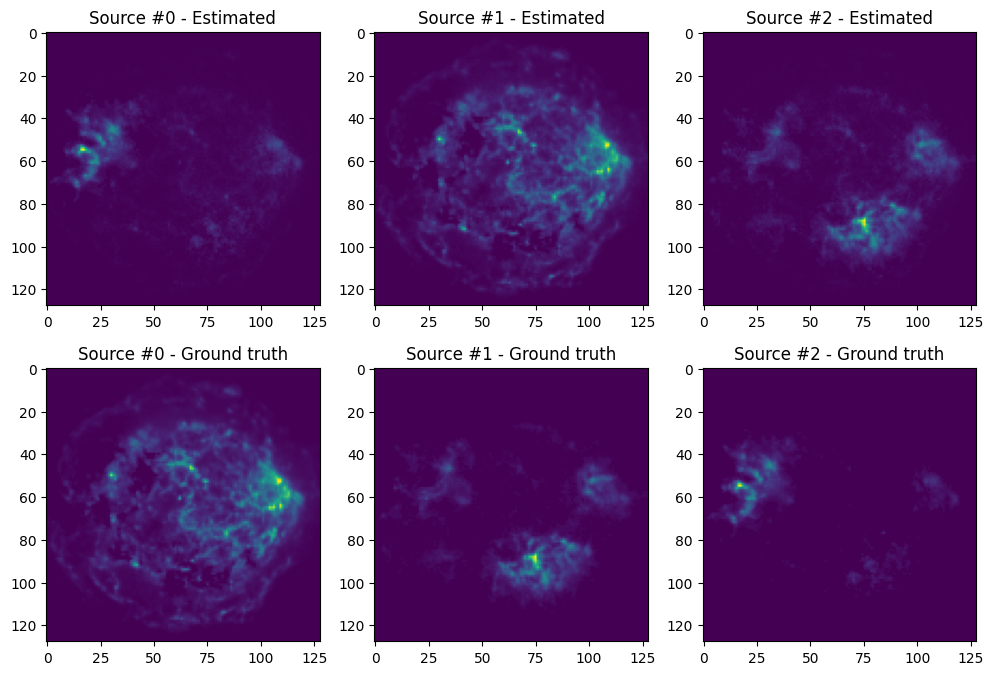

In [34]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(128, 128))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

On the less bright images, this methods bring more details. Visually, these source images seem closer to the original one.

## Complex model

## GMCA

In [16]:
A_est, S_est = GMCA(X_complex_model.reshape(40,-1), n_sources=3, max_iter=100)

### results

GMCA is completely off on this, whatever number of iterations we select and initialisation. Though, it gets some of the resulting mixing so maybe we could leverage it as an initialisation..

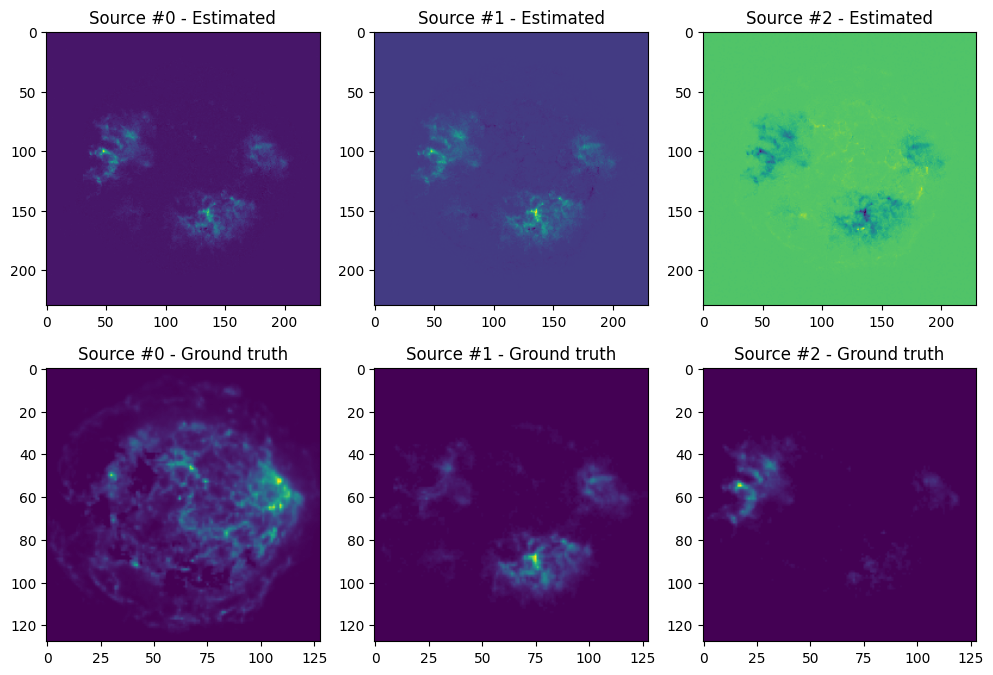

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(230, 230))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

## PALM method 

In [26]:
A_est, S_est, it = PALM(X_complex_model.reshape(40,-1), A_est, S_est.reshape(3,-1), lamb=1e-2, itmax=100)

itmax 100


### Results

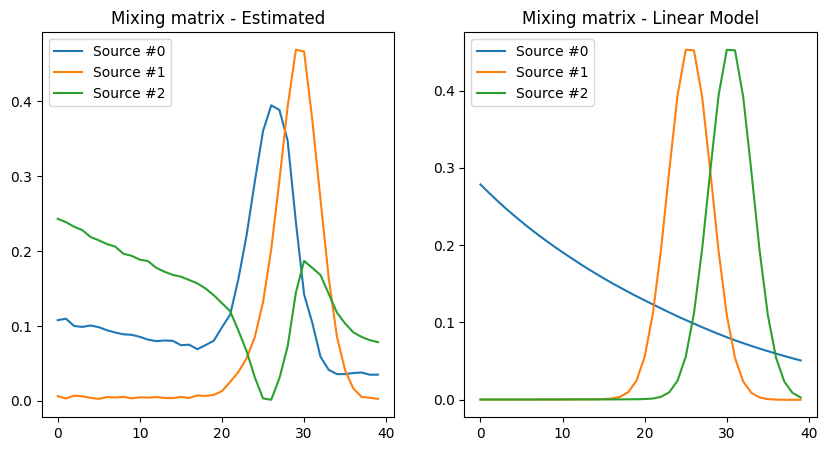

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Linear Model")
plt.show()

We can see in the figure above that the mixing matrix is reconstructed well for most of the spectrum, except for a small range around 30 where sources overlap more significantly. Interestingly, the two rays have different heights in the predicted mixture while they are equal in the ground truth.

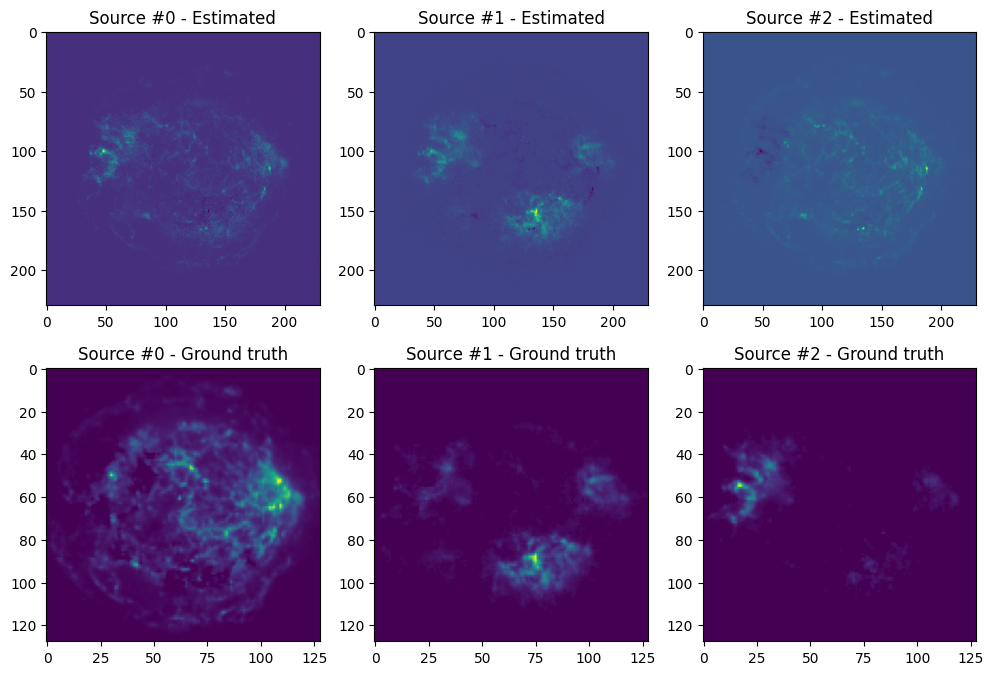

In [29]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(230, 230))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

Even though we miss some details, the source reconstruction quality is visually quite appealing and you can tell which source is which.

## minvolNMF method 

In [34]:
n_sources = 3

X_linear_2d = X_complex_model.reshape(X_complex_model.shape[0], -1)
K_SPA = simpleSPA(X_linear_2d, n_sources)

A_SPA = X_linear_2d[:, K_SPA]
[A_est, S_est, _, _, _] = minvolNMF(X_linear_2d,W=A_SPA,H=0.1 + np.random.rand(A_SPA.shape[1], X_linear_2d.shape[1]),r=n_sources,lamb=1.,maxiter=1000,target=0.05,model=1)

Max residual 113.59603607515353
Max residual 58.26599207699182
Max residual 28.57952517076345
100
200
300
400
500
600
700
800
900


### Results

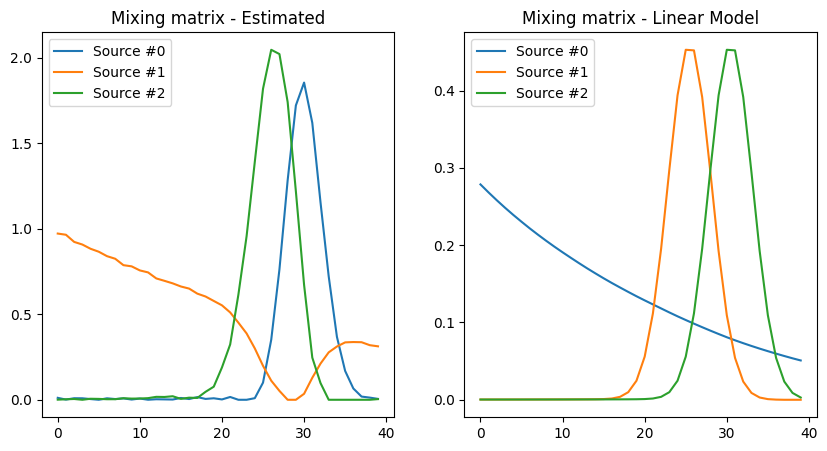

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Linear Model")
plt.show()

minvolNMF leads to better results. There is still a misprediction of the sources around the overlapping area but in the lowest values of $x$, the sources are predicted way better than the previous methods: this methods correctly predicts the mixing for all sources for $x < 20$.

However, the difference in height for the 2 rays is still present and this method doesn't solve this issue.

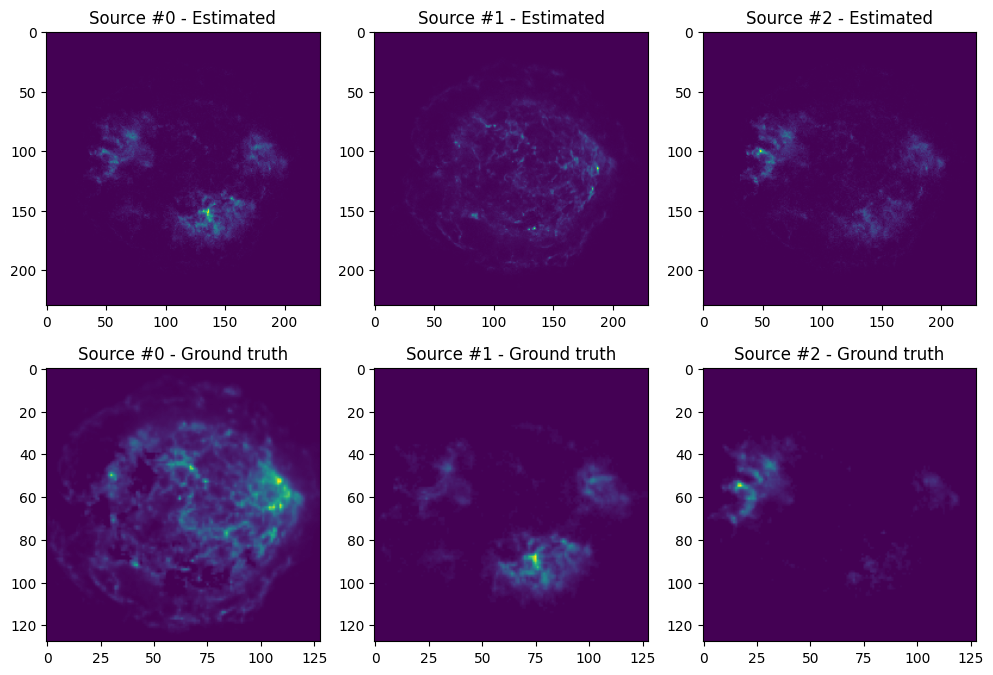

In [36]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(230, 230))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

The MinVol is the method that gives the results that are he original one.

## Real data

## GMCA

In [37]:
A_est, S_est = GMCA(X_real_data.reshape(40,-1), n_sources=3, max_iter=100)

### Results

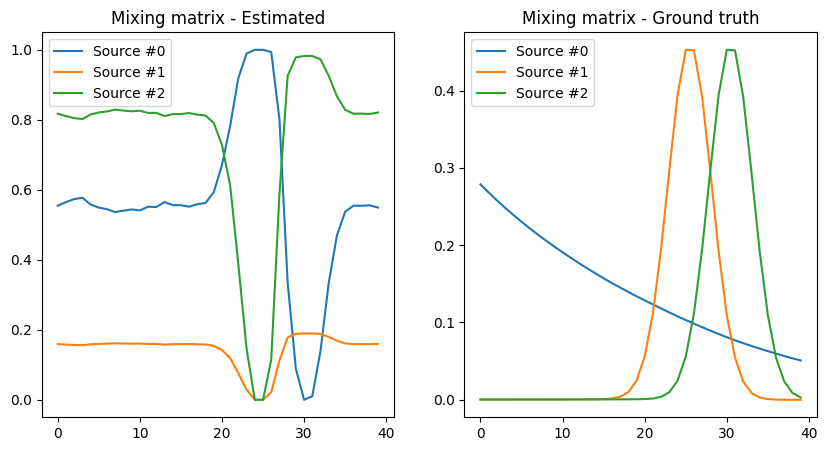

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

GMCA seems once again not a good method

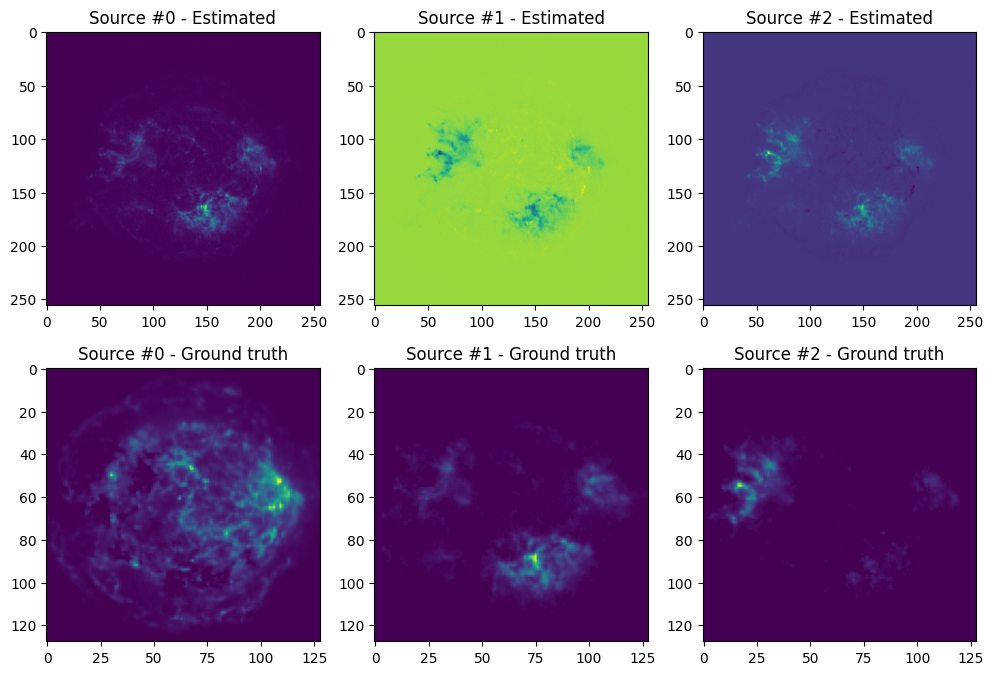

In [42]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(256, 256))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

## PALM method 

In [44]:
A_est, S_est, it = PALM(X_real_data.reshape(40,-1), A_est, S_est.reshape(3,-1), lamb=1e-2, itmax=100)

itmax 100


### Results

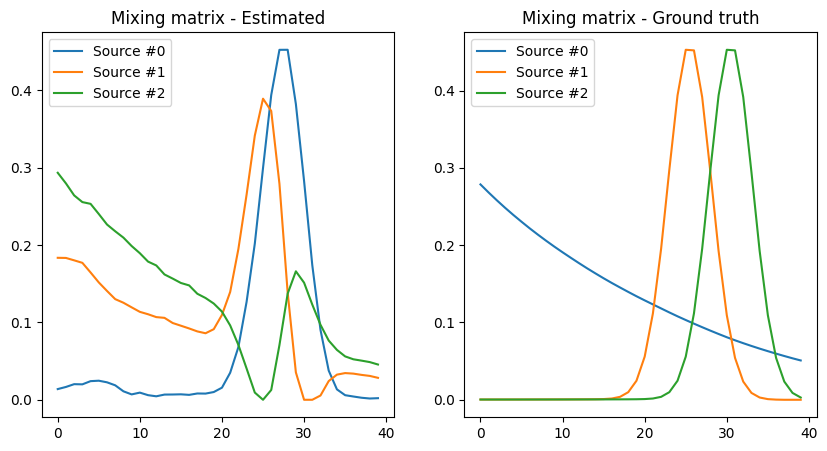

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

We can see in the figure above that the mixing matrix is reconstructed well for most of the spectrum, except for a small range around 30 where sources overlap more significantly. Interestingly, the two rays have different heights in the predicted mixture while they are equal in the ground truth.

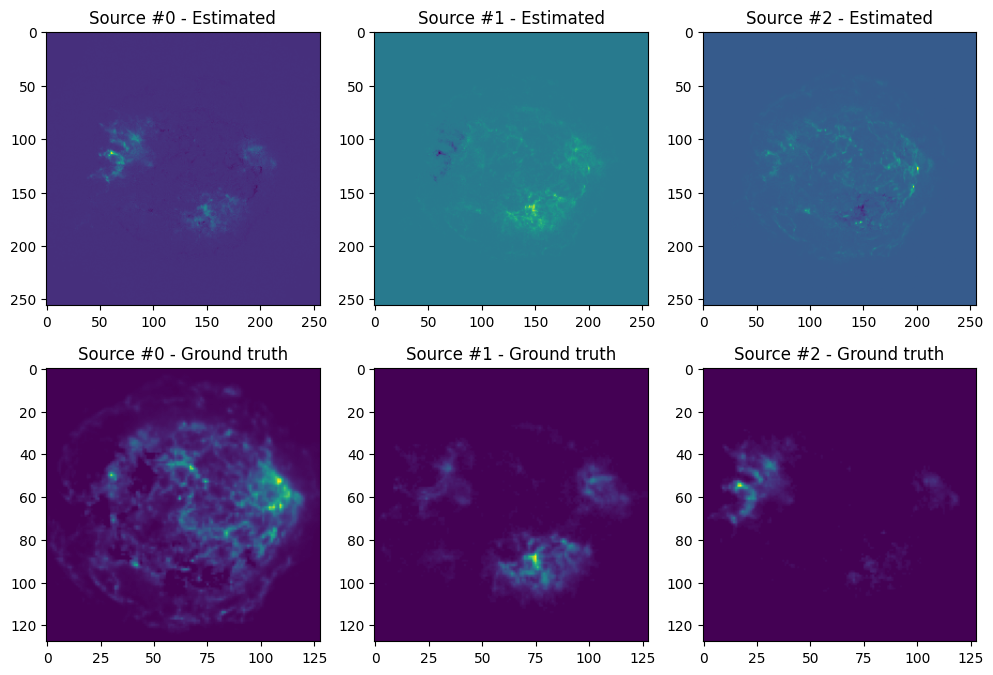

In [46]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(256, 256))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

Even though we miss some details, the source reconstruction quality is visually quite appealing and you can tell which source is which.

## minvolNMF method 

In [47]:
n_sources = 3

X_linear_2d = X_real_data.reshape(X_real_data.shape[0], -1)
K_SPA = simpleSPA(X_linear_2d, n_sources)

A_SPA = X_linear_2d[:, K_SPA]
[A_est, S_est, _, _, _] = minvolNMF(X_linear_2d,W=A_SPA,H=0.1 + np.random.rand(A_SPA.shape[1], X_linear_2d.shape[1]),r=n_sources,lamb=1.,maxiter=1000,target=0.05,model=1)

Max residual 122.89053788882353
Max residual 119.49802833065728
Max residual 29.47269959756909
100
200
300
400
500
600
700
800
900


### Results

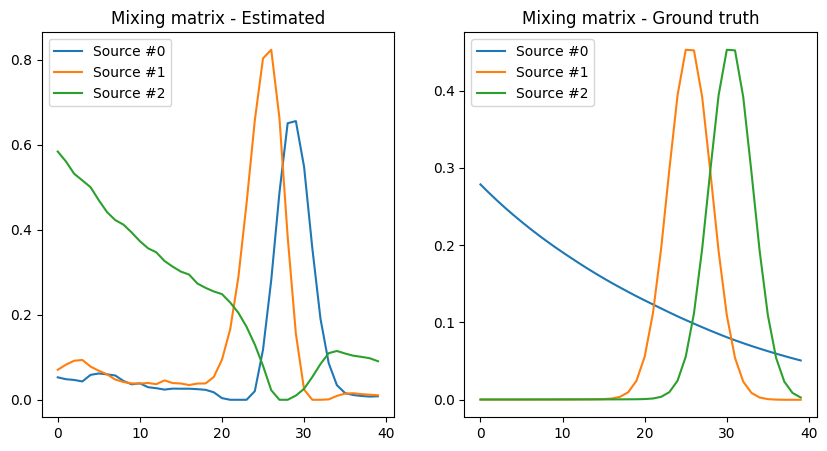

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for source_idx, source in enumerate(A_est.T):
    ax[0].plot(source, label=f"Source #{source_idx}")
ax[0].legend()
ax[0].set_title("Mixing matrix - Estimated")

for source_idx, source in enumerate(A_linear_model.T):
    ax[1].plot(source, label=f"Source #{source_idx}")
ax[1].legend()
ax[1].set_title("Mixing matrix - Ground truth")
plt.show()

minvolNMF leads to better results. There is still a misprediction of the sources around the overlapping area but in the lowest values of $x$, the sources are predicted way better than the previous methods: this methods correctly predicts the mixing for all sources for $x < 20$.

However, the difference in height for the 2 rays is still present and this method doesn't solve this issue.

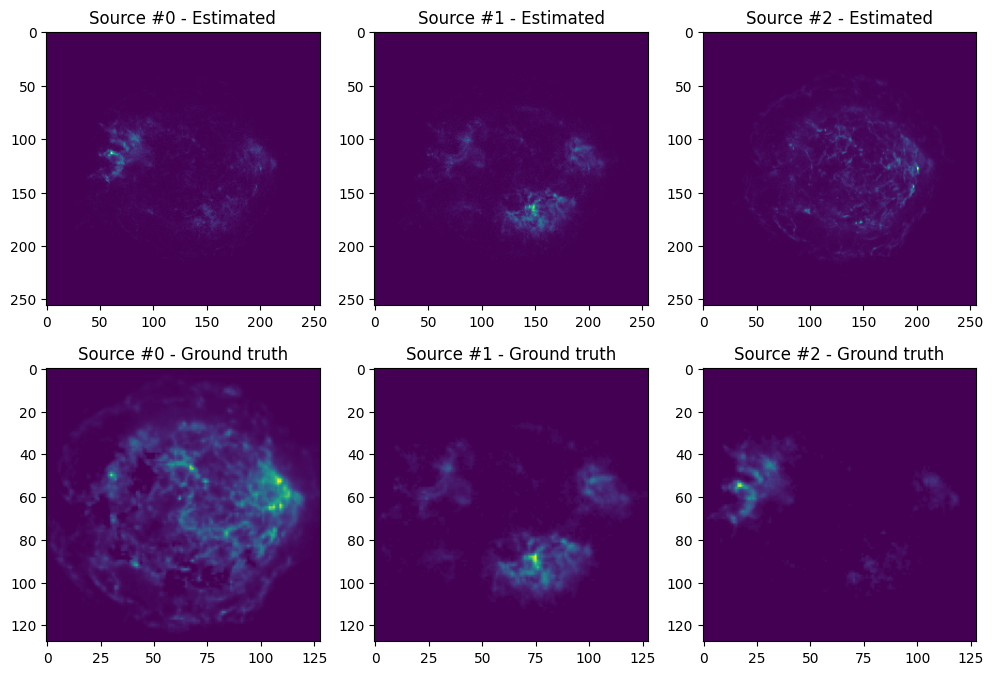

In [49]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for idx, source in enumerate(S_est):
    ax[0, idx].imshow(source.reshape(256, 256))
    ax[0, idx].set_title(f"Source #{idx} - Estimated")
for idx, source in enumerate(S_all_models):
    ax[1, idx].imshow(source)
    ax[1, idx].set_title(f"Source #{idx} - Ground truth")
plt.show()

On the less bright images, this methods bring more details. Visually, these source images seem closer to the original one.